## Part 3 — Machine Learning: predict no-shows and choose the model honestly

# Task 3.1 : Features, split and baseline

In [ ]:
# Step 1 : Features, split and baseline

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
# make a copy of the cleaned dataset

df_model = df.copy()

#step 1 : Select the required features

features = [
    'age',
    'distance_km',
    'fee_inr',
    'lead_days',
    'prior_no_shows',
    'reminder_sent',
    'booking_channel',
    'visit_type'

]

# define the target variable

target = 'no_show'

# separate feature and target

x = df_model[features].copy()

y = df_model[target].copy()

# covert yes/no columns into 1/0

for col in ['reminder_sent']:
    x[col] = x[col].map({'Yes': 1, 'No' : 0})

# convert categorical columns into numerical columns

x = pd.get_dummies(
    x,
    columns = ['booking_channel','visit_type'],
    drop_first = True,
    dtype = int
)

# split the data into training and testing sets

x_train, x_test , y_train, y_test = train_test_split(
   x,
   y,
   test_size = 0.20,
   random_state = 42,
   stratify = y
)
# check missing values
print("Missing values in x_train", x_train.isnull().sum().sum())

print("Missing values in x_test:", x_test.isnull().sum().sum())
# check the results

print("Training features:", x_train.shape)

print("Testing features:", x_test.shape)

print("\nTraining target:")

print(y_train.value_counts())

print("\nTesting target:")

print(y_test.value_counts())







Missing values in x_train 0
Missing values in x_test: 0
Training features: (792, 9)
Testing features: (198, 9)

Training target:
no_show
0    618
1    174
Name: count, dtype: int64

Testing target:
no_show
0    154
1     44
Name: count, dtype: int64


In [ ]:
# step 2: reminder_sent column

x['reminder_sent'] = (
    df_model['reminder_sent']
    .map({'Yes' : 1, 'No' : 0})
)



# step 3.2 : Logistic Regression

In [ ]:


from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score,classification_report

# create the model

model = LogisticRegression(

  max_iter = 1000,
  random_state = 42
)

# Train the model

model.fit(x_train,y_train)

# make predictions

y_pred = model.predict(x_test)

# Calculate accuracy

accuracy = accuracy_score(y_test , y_pred)

# Display classification report

print("\nclassification Report:")

print(classification_report(y_test,y_pred))





classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87       154
           1       0.56      0.34      0.42        44

    accuracy                           0.79       198
   macro avg       0.69      0.63      0.65       198
weighted avg       0.77      0.79      0.77       198



In [ ]:
# Improved logistic regression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# create the improved model
model_balanced = LogisticRegression(

        max_iter = 1000,
        random_state = 42,
        class_weight = 'balanced'
)

# Train the model

model_balanced.fit(x_train,y_train)

# Make predictions

y_pred_balanced = model_balanced.predict(x_test)

# Calculate accuracy

accuracy_balanced = accuracy_score(
    y_test, y_pred_balanced
)

print("Improved Model Accuracy:", accuracy_balanced)

# Display classification report

print("\nImproved Classification Report:")

print(classification_report(y_test,y_pred_balanced))






Improved Model Accuracy: 0.6818181818181818

Improved Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.68      0.77       154
           1       0.38      0.68      0.49        44

    accuracy                           0.68       198
   macro avg       0.63      0.68      0.63       198
weighted avg       0.77      0.68      0.71       198



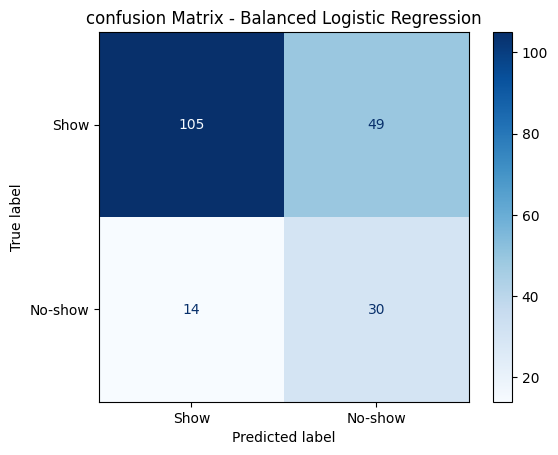

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# create confusion matrix
cm = confusion_matrix(y_test, y_pred_balanced)

# Display confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = ['Show' , 'No-show']
)

disp.plot(cmap = 'Blues')

plt.title('confusion Matrix - Balanced Logistic Regression')
plt.show()

#Task 3.3 : Decision tree and overfitting

In [ ]:
# step 1 :
from sklearn.tree import DecisionTreeClassifier

# create the decision tree model

dt_model = DecisionTreeClassifier(
    random_state = 42
)

# Train the model
dt_model.fit(x_train,y_train)

# Make predictions
y_pred_tree = dt_model.predict(x_test)
print("Decision tree model trained successfully")

Decision tree model trained successfully


In [ ]:
# step 2 : evaluate the decision tree model

# calculate accuracy

tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)

# Display classification report

print("\nDecision Tree Classification Report:")

print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.7070707070707071

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.81       154
           1       0.35      0.36      0.36        44

    accuracy                           0.71       198
   macro avg       0.58      0.58      0.58       198
weighted avg       0.71      0.71      0.71       198



In [ ]:
# Step 3 : check for overfitting

#predict on training data

y_train_pred_tree = dt_model.predict(x_train)

# Calculate training accuracy

train_accuracy_tree = accuracy_score(y_train,y_train_pred_tree)

# calculate testing accuracy

test_accuracy_tree = accuracy_score(y_test,y_pred_tree)

print("Training Accuracy:", train_accuracy_tree)

print("Testing Accuracy:",test_accuracy_tree)

# Calculate the difference

print("Accuracy Difference:", train_accuracy_tree - test_accuracy_tree)


Training Accuracy: 1.0
Testing Accuracy: 0.7070707070707071
Accuracy Difference: 0.29292929292929293


In [ ]:
# Step 4 : Reduce overfitting

dt_model_limited = DecisionTreeClassifier(
    max_depth = 5,
    random_state = 42
)

# Train the limited model

dt_model_limited.fit(x_train, y_train)

# Make predictions

y_pred_limited = dt_model_limited.predict(x_test)

# Calculate training and testing accuracy
train_accuracy_limited = accuracy_score(
    y_train,
    dt_model_limited.predict(x_train)
)

test_accuracy_limited = accuracy_score(
    y_test,
    y_pred_limited
)

print("Limited Tree Training Accuracy:",train_accuracy_limited)

print("Limited Tree Testing Accuracy:",test_accuracy_limited)

print(
      "Accuracy Difference:",
    train_accuracy_limited - test_accuracy_limited
)


Limited Tree Training Accuracy: 0.8459595959595959
Limited Tree Testing Accuracy: 0.797979797979798
Accuracy Difference: 0.0479797979797979


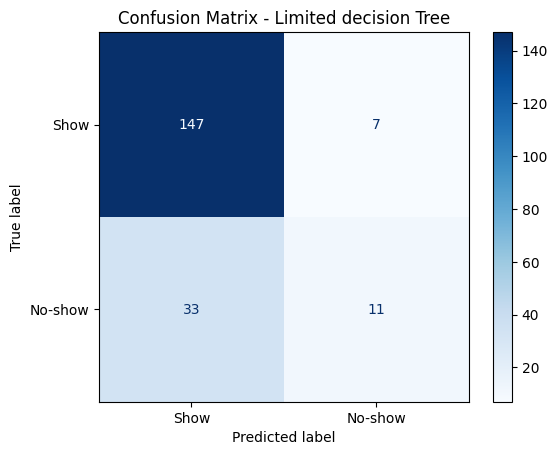

In [ ]:
# Step 4 - Confusion matrix for limited tree

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# calculate confusion matrix

cm_limited = confusion_matrix(y_test, y_pred_limited)

# Display confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm_limited,
    display_labels = ['Show', 'No-show']
)

disp.plot(cmap = 'Blues')

plt.title('Confusion Matrix - Limited decision Tree')

plt.show()

##Task 3.4 — Random forest and a comparison table

In [ ]:
# Step 1: Compare the models

from sklearn.metrics import accuracy_score, recall_score, f1_score

# Compare model performance
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Decision Tree',
        'Limited Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_limited)
    ],
    'No-show Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_limited)
    ],
    'No-show F1-score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_limited)
    ]
})

print(model_comparison.round(2))

                          Model  Accuracy  No-show Recall  No-show F1-score
0           Logistic Regression      0.79            0.34              0.42
1  Balanced Logistic Regression      0.68            0.68              0.49
2                 Decision Tree      0.71            0.36              0.36
3         Limited Decision Tree      0.80            0.25              0.35


In [ ]:
# Step 2: Train the Random Forest model

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(x_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(x_test)

print("Random Forest model trained successfully")

Random Forest model trained successfully


## Task 3.5 — Tune, choose the model and the threshold, then test once

In [ ]:
# Task 3.5: Feature Importance

# Get feature importance from the Random Forest
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display the top 3 features
print(feature_importance.head(3))

       Feature  Importance
3    lead_days    0.220606
1  distance_km    0.201871
0          age    0.188897


In [ ]:
# Step 2: Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the parameter combinations
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8]
}

# Create the Random Forest model
rf_model = RandomForestClassifier(random_state=42)

# Perform GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc"
)

# Train and find the best parameters
grid_search.fit(x_train, y_train)

# Display the best parameters and ROC-AUC score
print("Best Parameters:", grid_search.best_params_)
print("Best ROC-AUC Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'n_estimators': 100}
Best ROC-AUC Score: 0.7675065289687867


In [ ]:
# Step 3: Compare models using cross-validation

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the tuned Random Forest
rf_tuned = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Create the depth-3 Decision Tree
dt_depth3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Calculate 5-fold cross-validation ROC-AUC
rf_cv_score = cross_val_score(
    rf_tuned,
    x_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

dt_cv_score = cross_val_score(
    dt_depth3,
    x_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

print("Random Forest CV ROC-AUC:", rf_cv_score)
print("Decision Tree CV ROC-AUC:", dt_cv_score)

Random Forest CV ROC-AUC: 0.7675065289687867
Decision Tree CV ROC-AUC: 0.6849835315715586


In [ ]:
# Step 4 : Logistic Regression cross-validation

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

lr_cv_score = cross_val_score(
    lr_pipeline,
    x_train,
    y_train,
    cv=5,
    scoring='roc_auc'
).mean()

print("Logistic Regression CV ROC-AUC:", lr_cv_score)

Logistic Regression CV ROC-AUC: 0.7990484895767906


In [ ]:
# Step 5: Compare classification thresholds

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Get out-of-fold probabilities using Logistic Regression
y_prob_lr = cross_val_predict(
    lr_pipeline,
    x_train,
    y_train,
    cv=5,
    method='predict_proba'
)[:, 1]

# Compare thresholds
threshold_results = []

for threshold in [0.50, 0.35]:

    # Convert probabilities into predictions
    y_pred_threshold = (y_prob_lr >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_train,
        y_pred_threshold,
        pos_label=1
    )

    recall = recall_score(
        y_train,
        y_pred_threshold,
        pos_label=1
    )

    f1 = f1_score(
        y_train,
        y_pred_threshold,
        pos_label=1
    )

    # Count bookings flagged as No-show
    flagged = (y_pred_threshold == 1).sum()

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Number Flagged': flagged
    })

threshold_comparison = pd.DataFrame(threshold_results)

print(threshold_comparison.round(3))

   Threshold  Precision  Recall  F1-score  Number Flagged
0       0.50      0.446   0.718     0.551             280
1       0.35      0.336   0.845     0.480             438


In [ ]:
# Step 6: Final Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Select the final threshold
final_threshold = 0.50

# Train the winning model on the full training data
lr_pipeline.fit(x_train, y_train)

# Get predicted probabilities for the test data
y_prob_final = lr_pipeline.predict_proba(x_test)[:, 1]

# Apply the selected threshold
y_pred_final = (
    y_prob_final >= final_threshold
).astype(int)

# Calculate evaluation metrics
print("Final Model: Balanced Logistic Regression")
print("Selected Threshold:", final_threshold)

print(
    "\nTest Accuracy:",
    accuracy_score(y_test, y_pred_final)
)

print(
    "Test ROC-AUC:",
    roc_auc_score(y_test, y_prob_final)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final Model: Balanced Logistic Regression
Selected Threshold: 0.5

Test Accuracy: 0.6818181818181818
Test ROC-AUC: 0.7415879574970483

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.68      0.77       154
           1       0.38      0.68      0.49        44

    accuracy                           0.68       198
   macro avg       0.63      0.68      0.63       198
weighted avg       0.77      0.68      0.71       198

Confusion Matrix:
[[105  49]
 [ 14  30]]


In [ ]:
print("High-risk patients:", sum(y_pred_balanced))

High-risk patients: 79


In [ ]:
# identify high-risk patients
high_risk_patients = x_test[y_pred_final == 1].copy()

# Display the high-risk patients
print("Number of high_risk patients:",len(high_risk_patients))

display(high_risk_patients.head(10))


Number of high_risk patients: 79


,age,distance_km,fee_inr,lead_days,prior_no_shows,reminder_sent,booking_channel_Phone,booking_channel_Walk-In,visit_type_Follow-up
218,52,11.7,950.0,33,0,1,0,0,0
695,44,8.3,750.0,8,1,0,1,0,0
250,39,22.9,750.0,21,0,0,0,0,0
432,33,12.0,850.0,20,0,0,1,0,0
860,42,6.3,450.0,12,3,1,1,0,1
714,37,7.2,450.0,20,1,0,0,0,1
208,57,10.2,600.0,18,1,0,1,0,1
273,26,20.7,700.0,16,1,1,0,1,0
1000,24,17.0,550.0,9,2,1,0,0,0
626,35,2.7,1000.0,4,0,0,1,0,0


the balanced Logistic Regression model achieved a test ROC-AUC of 0.742 and 68% recall for no-shows at a 0.50 threshold.

Final Conclusion
The objective of this project was to predict whether a patient would miss a scheduled appointment. I compared Logistic Regression, Decision Tree, and Random Forest models using 5-fold cross-validation with ROC-AUC.

Balanced Logistic Regression was selected based on its cross-validation performance. A classification threshold of 0.50 was chosen because it gave a better F1-score than the 0.35 threshold during threshold comparison.

On the held-out test set, the final model achieved 68.2% accuracy and 0.742 ROC-AUC. It identified 30 of 44 actual no-shows, giving a no-show recall of 68%. However, its no-show precision was 38%, meaning some appointments flagged as likely no-shows would still take place.

The model may help identify patients for additional reminders, but its predictions should be used with consideration for the cost of unnecessary reminders.

In [ ]:
# Create the high-risk patient dataset
high_risk_patients = x_test[y_pred_final == 1].copy()

# Add actual and predicted outcomes
high_risk_patients["actual_no_show"] = y_test.loc[
    high_risk_patients.index
]

high_risk_patients["predicted_no_show"] = 1

# Save the results
high_risk_patients.to_csv(
    "high_risk_patients.csv",
    index=True
)

print("High-risk patient predictions saved successfully!")

High-risk patient predictions saved successfully!


In [ ]:
import shutil

shutil.copy(
    "high_risk_patients.csv",
    "/content/drive/MyDrive/GenAI_Project_Results/high_risk_patients.csv"
)

print("High-risk patient file saved to Google Drive!")

High-risk patient file saved to Google Drive!
